In [1]:
import pickle
import os
import ROOT
import numpy as np
import matplotlib.pyplot as plt

Welcome to JupyROOT 6.28/00


In [5]:
from ROOT import TCanvas, TColor, TGaxis, TH1F, TPad
from ROOT import kBlack, kBlue, kRed, kGray, kGreen, kTeal, kCyan, kAzure, kViolet, kMagenta, kPink, kOrange, kYellow, kSpring
ROOT.TH1.SetDefaultSumw2()

## Read in data

In [398]:
file_path_1 = "/t3home/rhampp/SVJ_GNN/output/LundNet5+_SVJ-QCD-TTJet-EW_vs12/_eval_new_ROC_AUC.pkl"

with open(file_path_1,'rb') as file:
    evaluation = pickle.load(file)
file.close()


In [399]:
file_path_2 = "/t3home/rhampp/SVJ_GNN/output/LundNet5+_SVJ-QCD-TTJet-EW_vs12/_train_ROC_AUC.pkl"

with open(file_path_2,'rb') as file:
    training = pickle.load(file)
file.close()


## Plot ROC

In [385]:
key = "SVJ_700_0p3_LN5p"
for key in evaluation:
    plt.plot(evaluation[key]["fpr"], evaluation[key]["tpr"], label = "evaluation")
    plt.plot(training[key]["fpr"], training[key]["tpr"], label = "training")
    plt.title(key)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.savefig("/t3home/rhampp/SVJ_GNN/ROC_Comparison/" + key + ".png")
    plt.close()
    

## Plot Scores

In [378]:
key = "SVJ_1000_0p3_LN5p"
parts = key.split("_")
qcd = True
bin_ks = 100

bin_sig = 30
bin_bkg = 30

label = f"$M_{{Z'}} = {parts[1]},  r_{{inv}} = 0.{parts[2].split('p')[1]}$"
rinv_value = f"0.{parts[2].split('p')[1]}"
m_z = parts[1]
score_sig = []
score_bkg = []
score_sig_train = []
score_bkg_train = []
weights_bkg = []
weights_bkg_train = []
weights_sig = []
weights_sig_train = []


for label, score, weight in zip(evaluation[key]["target_labels"], evaluation[key]["scores"],evaluation[key]["weight"] ):
    if label == 1:
        score_sig.append(score)
        weights_sig.append(weight)
    elif (qcd == True) & (label == 0):
        score_bkg.append(score)
        weights_bkg.append(weight)
        
for label, score, weight in zip(training[key]["target_labels"], training[key]["scores"], training[key]["weight"]):
    if label == 1:
        score_sig_train.append(score)
        weights_sig_train.append(weight)
    elif label == 0:
        score_bkg_train.append(score)
        weights_bkg_train.append(weight)
        
print(len(score_sig))
print(len(score_bkg))
print(len(score_bkg_train))
h_sig = ROOT.TH1F("" ,"score", bin_sig, 0, 1)
h_sig_train = ROOT.TH1F("","score", bin_sig, 0, 1)
h_bkg = ROOT.TH1F("","score", bin_bkg, 0, 1)
h_bkg_train = ROOT.TH1F("", "score", bin_bkg, 0, 1)

# for value, weight in zip(score_sig, weights_sig):
#     h_sig.Fill(value, weight)
# for value, weight in zip(score_bkg, weights_bkg):
#     h_bkg.Fill(value, weight)
# for value, weight in zip(score_sig_train, weights_sig_train):
#     h_sig_train.Fill(value, weight)
# for value, weight in zip(score_bkg_train, weights_bkg_train):
#     h_bkg_train.Fill(value, weight)
for value in score_sig:
    h_sig.Fill(value)
for value in score_bkg:
    h_bkg.Fill(value)
for value in score_sig_train:
    h_sig_train.Fill(value)
for value in score_bkg_train:
    h_bkg_train.Fill(value)

h_sig.Scale(1./h_sig.Integral())
h_sig_train.Scale(1./h_sig_train.Integral())
h_bkg.Scale(1./h_bkg.Integral())
h_bkg_train.Scale(1./h_bkg_train.Integral())

c1= kAzure
c2 = kRed
c3 = kGreen
c4 = kViolet

h_sig.SetLineColor(c1)
h_sig_train.SetLineColor(c2)
h_bkg.SetLineColor(c3)
h_bkg_train.SetLineColor(c4)



1478
347701
695380


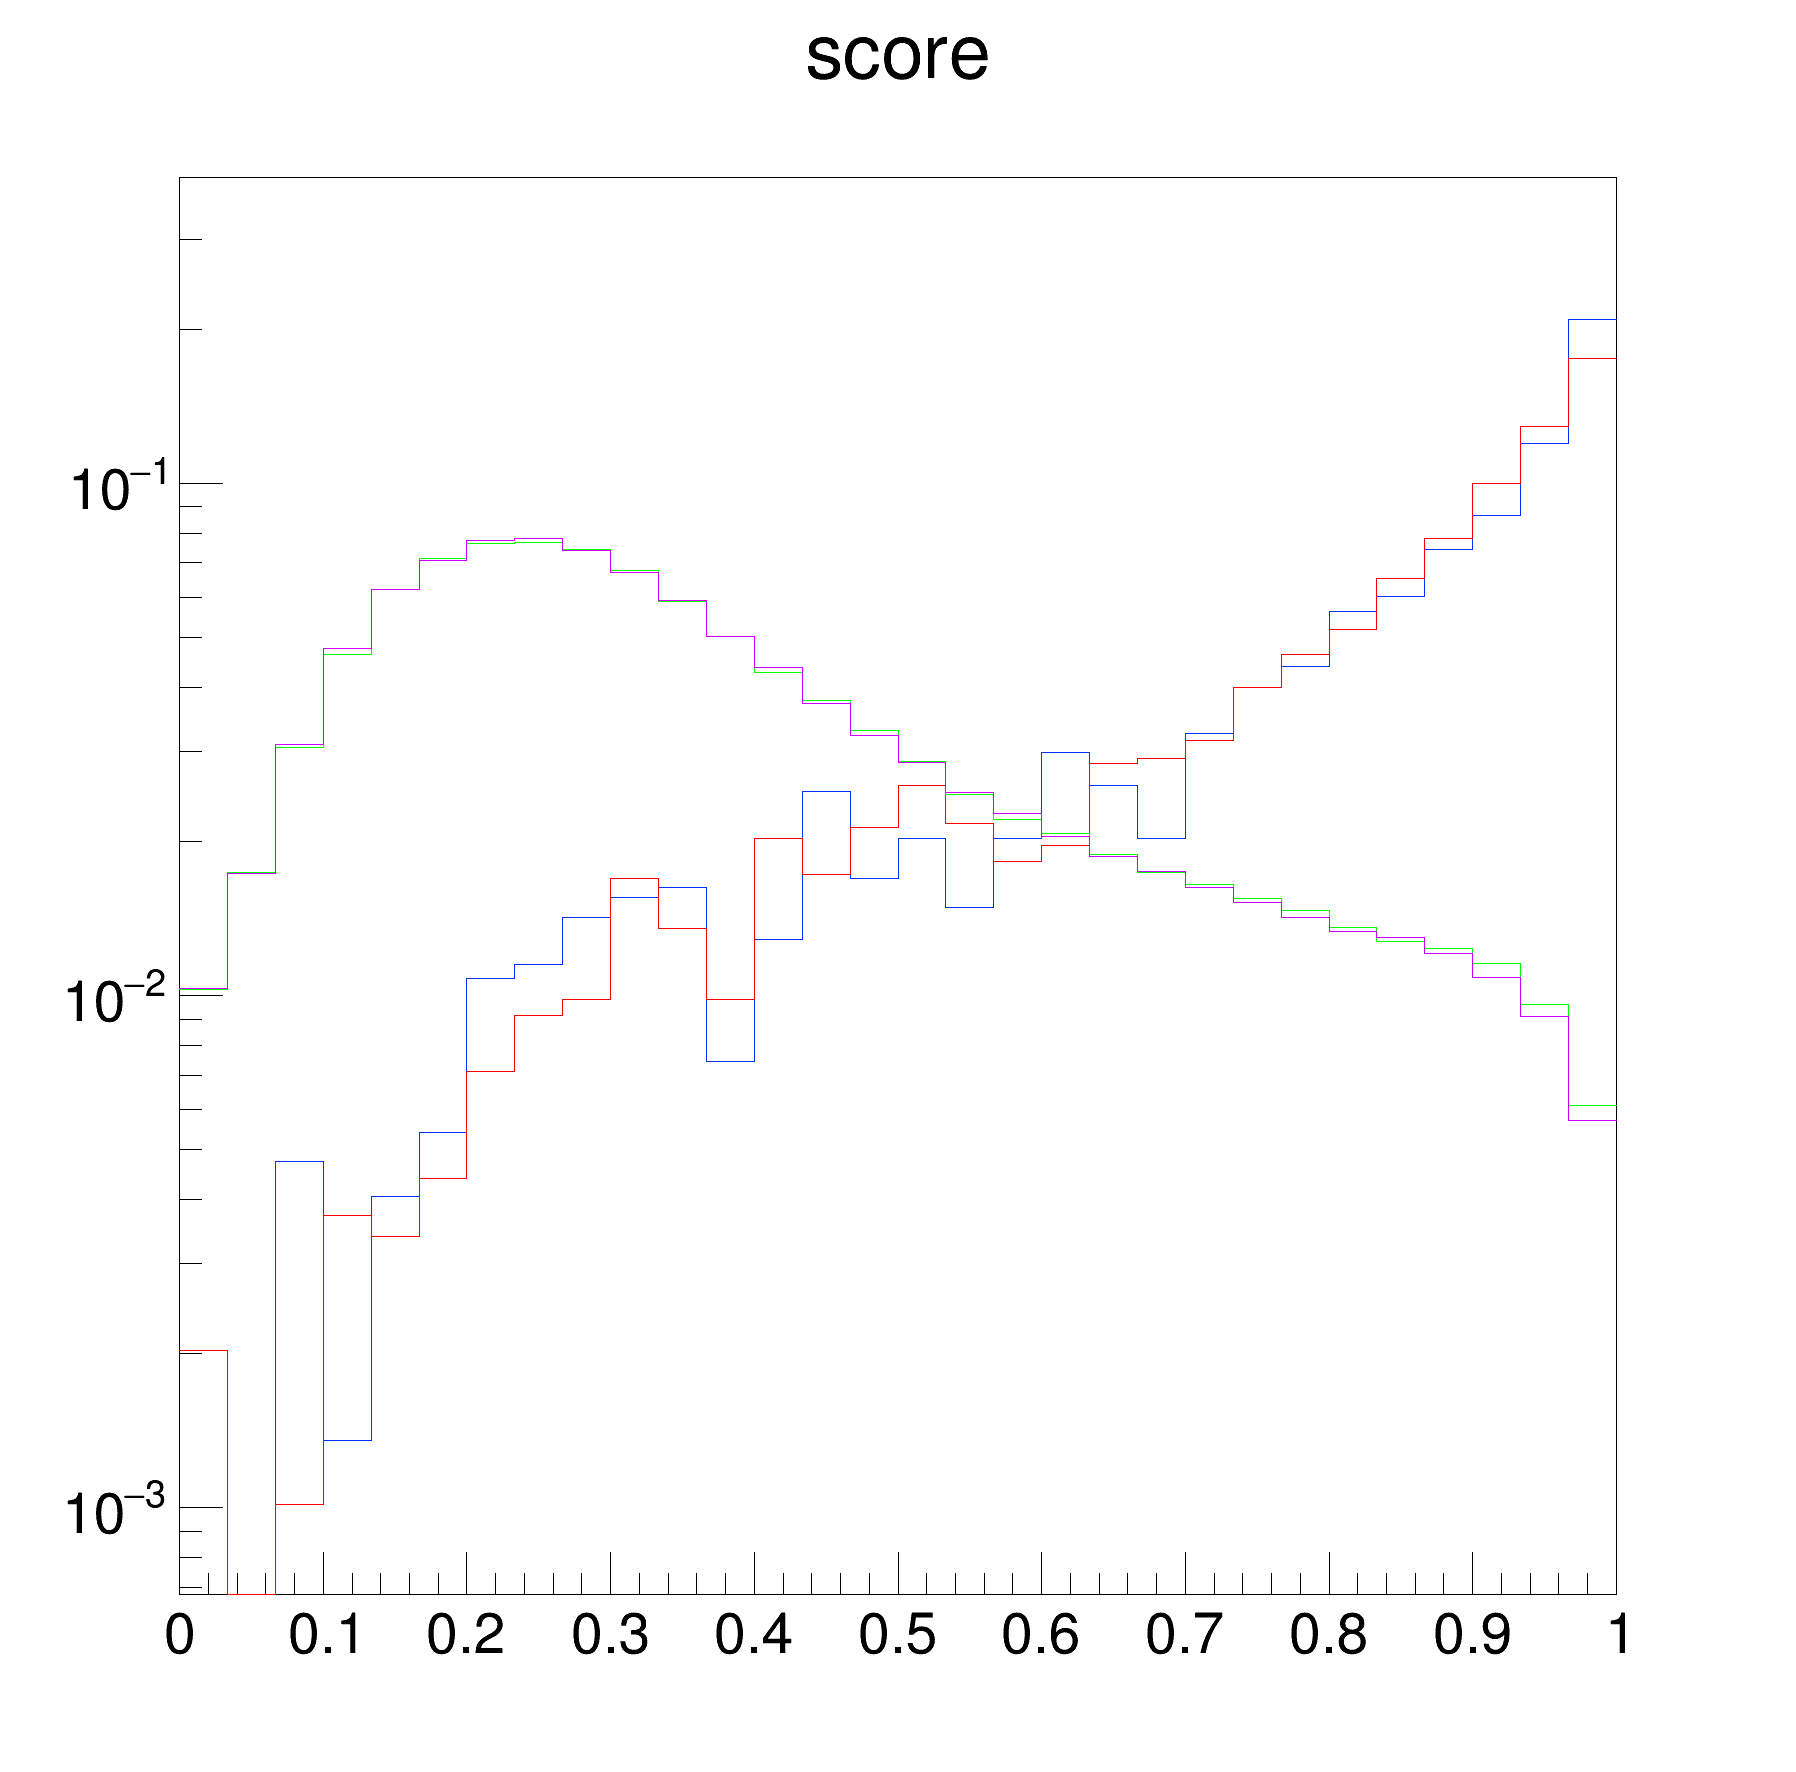

In [379]:
canvas = ROOT.TCanvas("","",1800, 1800)
canvas.cd()
canvas.SetLogy()
h_sig.SetStats(0)
h_sig.Draw("hist")
h_sig_train.Draw("hist same")
h_bkg.Draw("hist same")
h_bkg_train.Draw("hist same")

canvas.Draw()

In [380]:
ks_test_signal = h_sig.KolmogorovTest(h_sig_train)
ks_test_bkg = h_bkg.KolmogorovTest(h_bkg_train)

In [381]:
print(ks_test_bkg)
print(ks_test_signal)

0.003607821993278663
0.20183723544155477


In [382]:
score_bkg = np.array(score_bkg, dtype=np.float64)
score_bkg_train = np.array(score_bkg_train, dtype=np.float64)


In [371]:
ROOT.TMath.KolmogorovTest(len(score_bkg), score_bkg,len(score_bkg_train), score_bkg_train, "D")

0.0

 Kolmogorov Probability = 0, Max Dist = 0.501041


In [372]:
from scipy import stats



In [373]:
ks_statistic, p_value = stats.ks_2samp(score_bkg, score_bkg_train)
print(ks_statistic)
print(p_value)

0.003605727012751081
0.02171555278010356


In [374]:
# Perform the KS test
ks_statistic, p_value = stats.ks_2samp(h_sig, h_sig_train, method="asymp")
print(ks_statistic)
print(p_value)

ks_statistic, p_value = stats.ks_2samp(h_sig, h_sig_train, method="exact")
print(ks_statistic)
print(p_value)

0.09375
0.9964388803531499
0.09375
0.9993259137184929


In [375]:
# Perform the KS test

ks_statistic, p_value = stats.ks_2samp(h_bkg, h_bkg_train, method="asymp")
print(ks_statistic)
print(p_value)

ks_statistic, p_value = stats.ks_2samp(h_bkg, h_bkg_train, method="exact")
print(ks_statistic)
print(p_value)

0.0625
0.9999988657732874
0.0625
0.9999999976563841


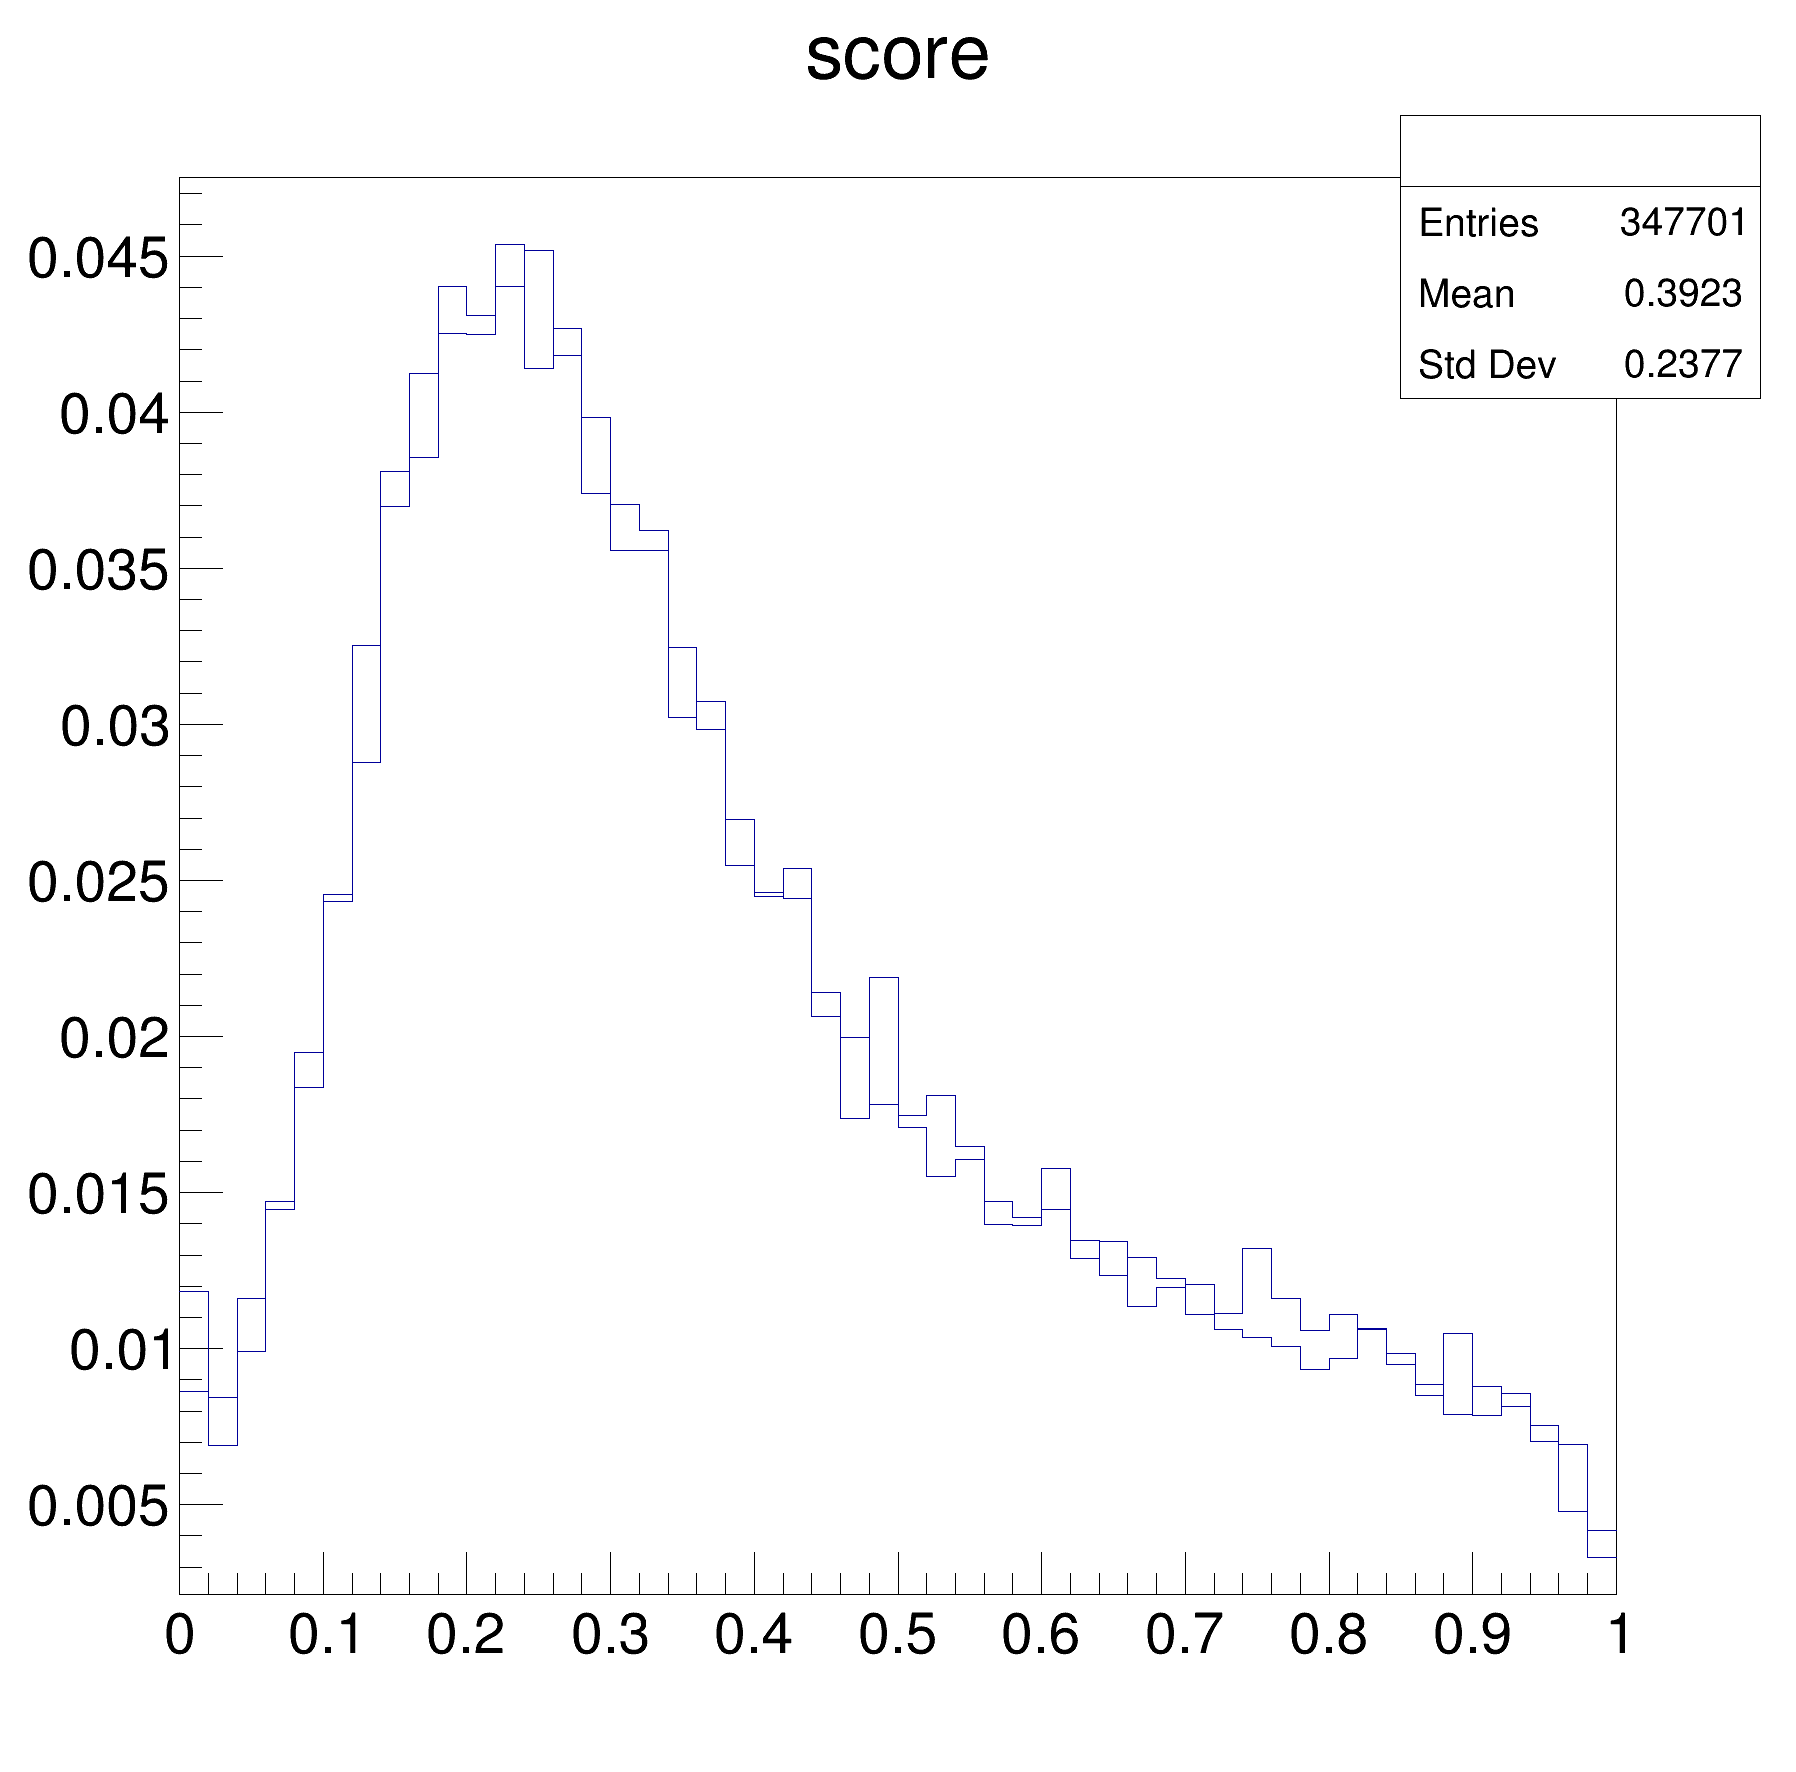

In [40]:
color_bkg = '#457B9D'
color_sig = 'firebrick'

evaluation_dict_1 = evaluation
evaluation_dict_2 = training
key = "SVJ_700_0p3_LN5p"
score_sig = []
score_bkg = []
score_sig_train = []
score_bkg_train = []
weights_bkg = []
weights_bkg_train = []
weights_sig = []
weights_sig_train = []
nbin = 15
for label, score, weight in zip(evaluation_dict_1[key]["target_labels"], evaluation_dict_1[key]["scores"],evaluation_dict_1[key]["weight"] ):
    if label == 1:
        score_sig.append(score)
        weights_sig.append(weight)
    elif label == 0:
        score_bkg.append(score)
        weights_bkg.append(weight)

for label, score, weight in zip(evaluation_dict_2[key]["target_labels"], evaluation_dict_2[key]["scores"], evaluation_dict_2[key]["weight"]):
    if label == 1:
        score_sig_train.append(score)
        weights_sig_train.append(weight)
    elif label == 0:
        score_bkg_train.append(score)
        weights_bkg_train.append(weight)

# # Main Plot
# ax = plt.subplot2grid((4, 1), (0, 0), rowspan=3)
# # Plot Signal (Evaluation sample)
# ax.hist(score_sig, weights=weights_sig,range = (0,1), bins = nbin , density=True, color=color_sig, edgecolor=color_sig,linewidth = 0.9, linestyle='-', alpha = 0.5, histtype = 'stepfilled', label=f"Signal (evaluation sample)")

# # Plot Background (Evaluation sample)
# ax.hist(score_bkg, weights=weights_bkg, bins = nbin ,range = (0,1), density = True, color=color_bkg, edgecolor = color_bkg, linewidth = 0.9, linestyle='-',alpha = 0.5, histtype = 'stepfilled', label="Backgroud (evaluation sample)")

# # Plot Signal (Training sample)
# counts_sig_train, bin_edges_sig_train = np.histogram(score_sig_train,weights=weights_sig_train,range = (0,1),  bins=nbin, density = True)
# bin_centers_sig_train = (bin_edges_sig_train[:-1] + bin_edges_sig_train[1:]) / 2
# ax.scatter(bin_centers_sig_train, counts_sig_train, marker='+', color=color_sig, label = "Signal (training sample)")

# # Plot Background (Training sample)
# counts_bkg_train, bin_edges_bkg_train = np.histogram(score_bkg_train, weights = weights_bkg_train,range = (0,1),  bins=nbin, density = True)
# bin_centers_bkg_train = (bin_edges_bkg_train[:-1] + bin_edges_bkg_train[1:]) / 2
# ax.scatter(bin_centers_bkg_train, counts_bkg_train, marker='+', color=color_bkg, label = "Background (training sample)")

bin_ks = 50
## KS test
canvas = ROOT.TCanvas("","",1800, 1800)
canvas.cd()
h_sig = ROOT.TH1F("" ,"score", bin_ks, 0, 1)
h_sig_train = ROOT.TH1F("","score", bin_ks, 0, 1)
h_bkg = ROOT.TH1F("","score", bin_ks, 0, 1)
h_bkg_train = ROOT.TH1F("", "score", bin_ks, 0, 1)
for value, weight in zip(score_sig, weights_sig):
    h_sig.Fill(value, weight)
for value, weight in zip(score_bkg, weights_bkg):
    h_bkg.Fill(value, weight)
for value, weight in zip(score_sig_train, weights_sig_train):
    h_sig_train.Fill(value, weight)
for value, weight in zip(score_bkg_train, weights_bkg_train):
    h_bkg_train.Fill(value, weight)

h_sig.Scale(1./h_sig.Integral())
h_sig_train.Scale(1./h_sig_train.Integral())
h_bkg.Scale(1./h_bkg.Integral())
h_bkg_train.Scale(1./h_bkg_train.Integral())

c1= kAzure
c2 = kRed
c3 = kGreen
c4 = kViolet

h_sig.SetLineColor(c1)
h_sig_train.SetLineColor(c2)
h_bkg.SetLineColor(c3)
h_bkg_train.SetLineColor(c4)

h_sig.Draw("hist")
h_sig_train.Draw("hist same")
h_bkg.Draw("hist same")
h_bkg_train.Draw("hist same")


canvas.Draw()


In [97]:

ks_test_signal = h_sig.KolmogorovTest(h_sig_train)
ks_test_bkg = h_bkg.KolmogorovTest(h_bkg_train)

print(ks_test_bkg)
print(ks_test_signal)

5.130688983310285e-06
1.9301100250931326e-05


## Compare scores

In [404]:
def plot_scores(evaluation, training, MZ = "all"):
        
    color_bkg = '#457B9D'
    color_sig = 'firebrick'

    for key_eva, key_train in zip(evaluation, training):
        if key_eva == key_train:
            print("Keys match")
            key = key_eva
        else:
            print("Keys do not match")
            break
        
        plt.figure(figsize=(7, 7), dpi = 150)

        parts = key.split("_")
        if (MZ != "all") and (parts[1] != MZ):
            continue
        label = f"$M_{{Z'}} = {parts[1]},  r_{{inv}} = 0.{parts[2].split('p')[1]}$"
        rinv_value = f"0.{parts[2].split('p')[1]}"
        m_z = parts[1]
        score_sig_eva = []
        score_bkg_eva = []
        score_sig_train = []
        score_bkg_train = []
        weights_bkg_eva = []
        weights_bkg_train = []
        weights_sig_eva = []
        weights_sig_train = []
        nbin = 30
        for label, score, weight in zip(evaluation[key]["target_labels"], evaluation[key]["scores"],evaluation[key]["weight"]):
            if label == 1:
                score_sig_eva.append(score)
                weights_sig_eva.append(weight)
            elif label == 0:
                score_bkg_eva.append(score)
                weights_bkg_eva.append(weight)

        for label, score, weight in zip(training[key]["target_labels"], training[key]["scores"], training[key]["weight"]):
            if label == 1:
                score_sig_train.append(score)
                weights_sig_train.append(weight)
            elif label == 0:
                score_bkg_train.append(score)
                weights_bkg_train.append(weight)

        # # Main Plot
        ax = plt.subplot2grid((4, 1), (0, 0), rowspan=3)
        # Plot Signal (Evaluation sample)
        ax.hist(score_sig_eva,range = (0,1), bins = nbin , density=True, color=color_sig, edgecolor=color_sig,linewidth = 0.9, linestyle='-', alpha = 0.5, histtype = 'stepfilled', label=f"Signal (evaluation sample)")
        
        # Plot Background (Evaluation sample)
        ax.hist(score_bkg_eva, bins = nbin ,range = (0,1), density = True, color=color_bkg, edgecolor = color_bkg, linewidth = 0.9, linestyle='-',alpha = 0.5, histtype = 'stepfilled', label="Backgroud (evaluation sample)")
       
        # Plot Signal (Training sample)
        counts_sig_train, bin_edges_sig_train = np.histogram(score_sig_train,range = (0,1),  bins=nbin, density = True)
        bin_centers_sig_train = (bin_edges_sig_train[:-1] + bin_edges_sig_train[1:]) / 2
        ax.scatter(bin_centers_sig_train, counts_sig_train, marker='+', color=color_sig, label = "Signal (training sample)")
        
        # Plot Background (Training sample)
        counts_bkg_train, bin_edges_bkg_train = np.histogram(score_bkg_train,range = (0,1),  bins=nbin, density = True)
        bin_centers_bkg_train = (bin_edges_bkg_train[:-1] + bin_edges_bkg_train[1:]) / 2
        ax.scatter(bin_centers_bkg_train, counts_bkg_train, marker='+', color=color_bkg, label = "Background (training sample)")

        bin_ks = 300
        ## KS test
        canvas = ROOT.TCanvas("","",1800, 1800)
        canvas.cd()
        h_sig = ROOT.TH1F("" ,"score", bin_ks, 0, 1)
        h_sig_train = ROOT.TH1F("","score", bin_ks, 0, 1)
        h_bkg = ROOT.TH1F("","score", bin_ks, 0, 1)
        h_bkg_train = ROOT.TH1F("", "score", bin_ks, 0, 1)
        for value, weight in zip(score_sig_eva, weights_sig_eva):
            h_sig.Fill(value)
        for value, weight in zip(score_bkg_eva, weights_bkg_eva):
            h_bkg.Fill(value)
        for value, weight in zip(score_sig_train, weights_sig_train):
            h_sig_train.Fill(value)
        for value, weight in zip(score_bkg_train, weights_bkg_train):
            h_bkg_train.Fill(value)


        h_sig.Scale(1./h_sig.Integral())
        h_sig_train.Scale(1./h_sig_train.Integral())
        h_bkg.Scale(1./h_bkg.Integral())
        h_bkg_train.Scale(1./h_bkg_train.Integral())
    


        h_sig.Draw("hist")
        h_sig_train.Draw("hist same")
        h_bkg.Draw("hist same")
        h_bkg_train.Draw("hist same")



        # Perform the KS test
        # _, ks_test_signal = stats.ks_2samp(h_sig, h_sig_train)
        # _, ks_test_bkg = stats.ks_2samp(h_bkg, h_bkg_train)
        ks_test_signal = h_sig.KolmogorovTest(h_sig_train)
        ks_test_bkg = h_bkg.KolmogorovTest(h_bkg_train)
   
        plt.ylabel("a.u.")

        ## Legend
        legend = ax.legend(title = f"$M_{{Z'}} = $ {m_z} GeV, $r_{{inv}} = $ {rinv_value}", loc=[0.02,0.85], edgecolor = 'white', ncols = 2, fontsize = 8)
        legend._legend_box.align = 'left'
 
        ax.annotate(f"Kolmogorov-Smirnov Test Signal (Background): {ks_test_signal:.3f} ({ks_test_bkg:.3f})", xy = [0.05,0.02], xycoords='axes fraction',fontsize=8)

        plt.yscale('log')
        plt.ylim(0,10)
        ## Ratio plots

        plt.subplot2grid((4, 1), (3, 0))
        
        counts_sig_eval, _ = np.histogram(score_sig_eva, bins=nbin, range = (0,1), weights=weights_sig_eva, density=True)
        counts_bkg_eval, _ = np.histogram(score_bkg_eva, bins=nbin, range = (0,1), weights=weights_bkg_eva, density=True)

        ratio_sig = np.divide(counts_sig_eval, counts_sig_train, out=np.zeros_like(counts_sig_eval), where=counts_sig_train!=0)
        ratio_bkg = np.divide(counts_bkg_eval, counts_bkg_train, out=np.zeros_like(counts_bkg_eval), where=counts_bkg_train!=0)

        error_sig_eval = np.sqrt(counts_sig_eval)
        error_bkg_eval = np.sqrt(counts_bkg_eval)
        error_sig_train = np.sqrt(counts_sig_train)
        error_bkg_train = np.sqrt(counts_bkg_train)
        
        ratio_sig_err = ratio_sig * np.sqrt((error_sig_eval / counts_sig_eval)**2 + (error_sig_train / counts_sig_train)**2)
        ratio_bkg_err = ratio_bkg * np.sqrt((error_bkg_eval / counts_bkg_eval)**2 + (error_bkg_train / counts_bkg_train)**2)

        plt.errorbar(bin_centers_sig_train, ratio_sig, yerr=ratio_sig_err,  fmt='+', linewidth = 0.9,  color=color_sig, label="Signal Ratio")
        plt.errorbar(bin_centers_bkg_train, ratio_bkg, yerr=ratio_bkg_err, fmt='+', linewidth = 0.9, color=color_bkg, label="Background Ratio")
        plt.ylim(-4,4)
        
        plt.axhline(y=1, color='gray', linestyle='-', linewidth = 0.8)
        plt.xlabel("DNN Score")
        plt.ylabel("Ratio")
    
        
        plt.tight_layout()


    
        plt.savefig("/t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/" + key + ".png")
        print(f"Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/" + key + ".png")
        plt.close()
        




In [405]:
plot_scores(evaluation, training, MZ = "all")


Keys match


/tmp/ipykernel_17462/121970153.py:112: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,10)


Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_700_0p3_LN5p.png
Keys match


/tmp/ipykernel_17462/121970153.py:128: RuntimeWarning: invalid value encountered in divide
  ratio_sig_err = ratio_sig * np.sqrt((error_sig_eval / counts_sig_eval)**2 + (error_sig_train / counts_sig_train)**2)


Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_700_0p5_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_700_0p7_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_800_0p3_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_800_0p5_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_800_0p7_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_900_0p3_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_900_0p5_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_900_0p7_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_1000_0p3_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_1000_0p5_LN5p.png
Keys match
Plot saved in /t3home/rhampp/SVJ_GNN/ROC_Comparison/Score/SVJ_1000_0p7_LN5p.png
Keys match
Plot sa

In [38]:
from ROOT import TCanvas, TColor, TGaxis, TH1F, TPad
from ROOT import kBlack, kBlue, kRed, kGray, kGreen, kTeal, kCyan, kAzure, kViolet, kMagenta, kPink, kOrange, kYellow, kSpring


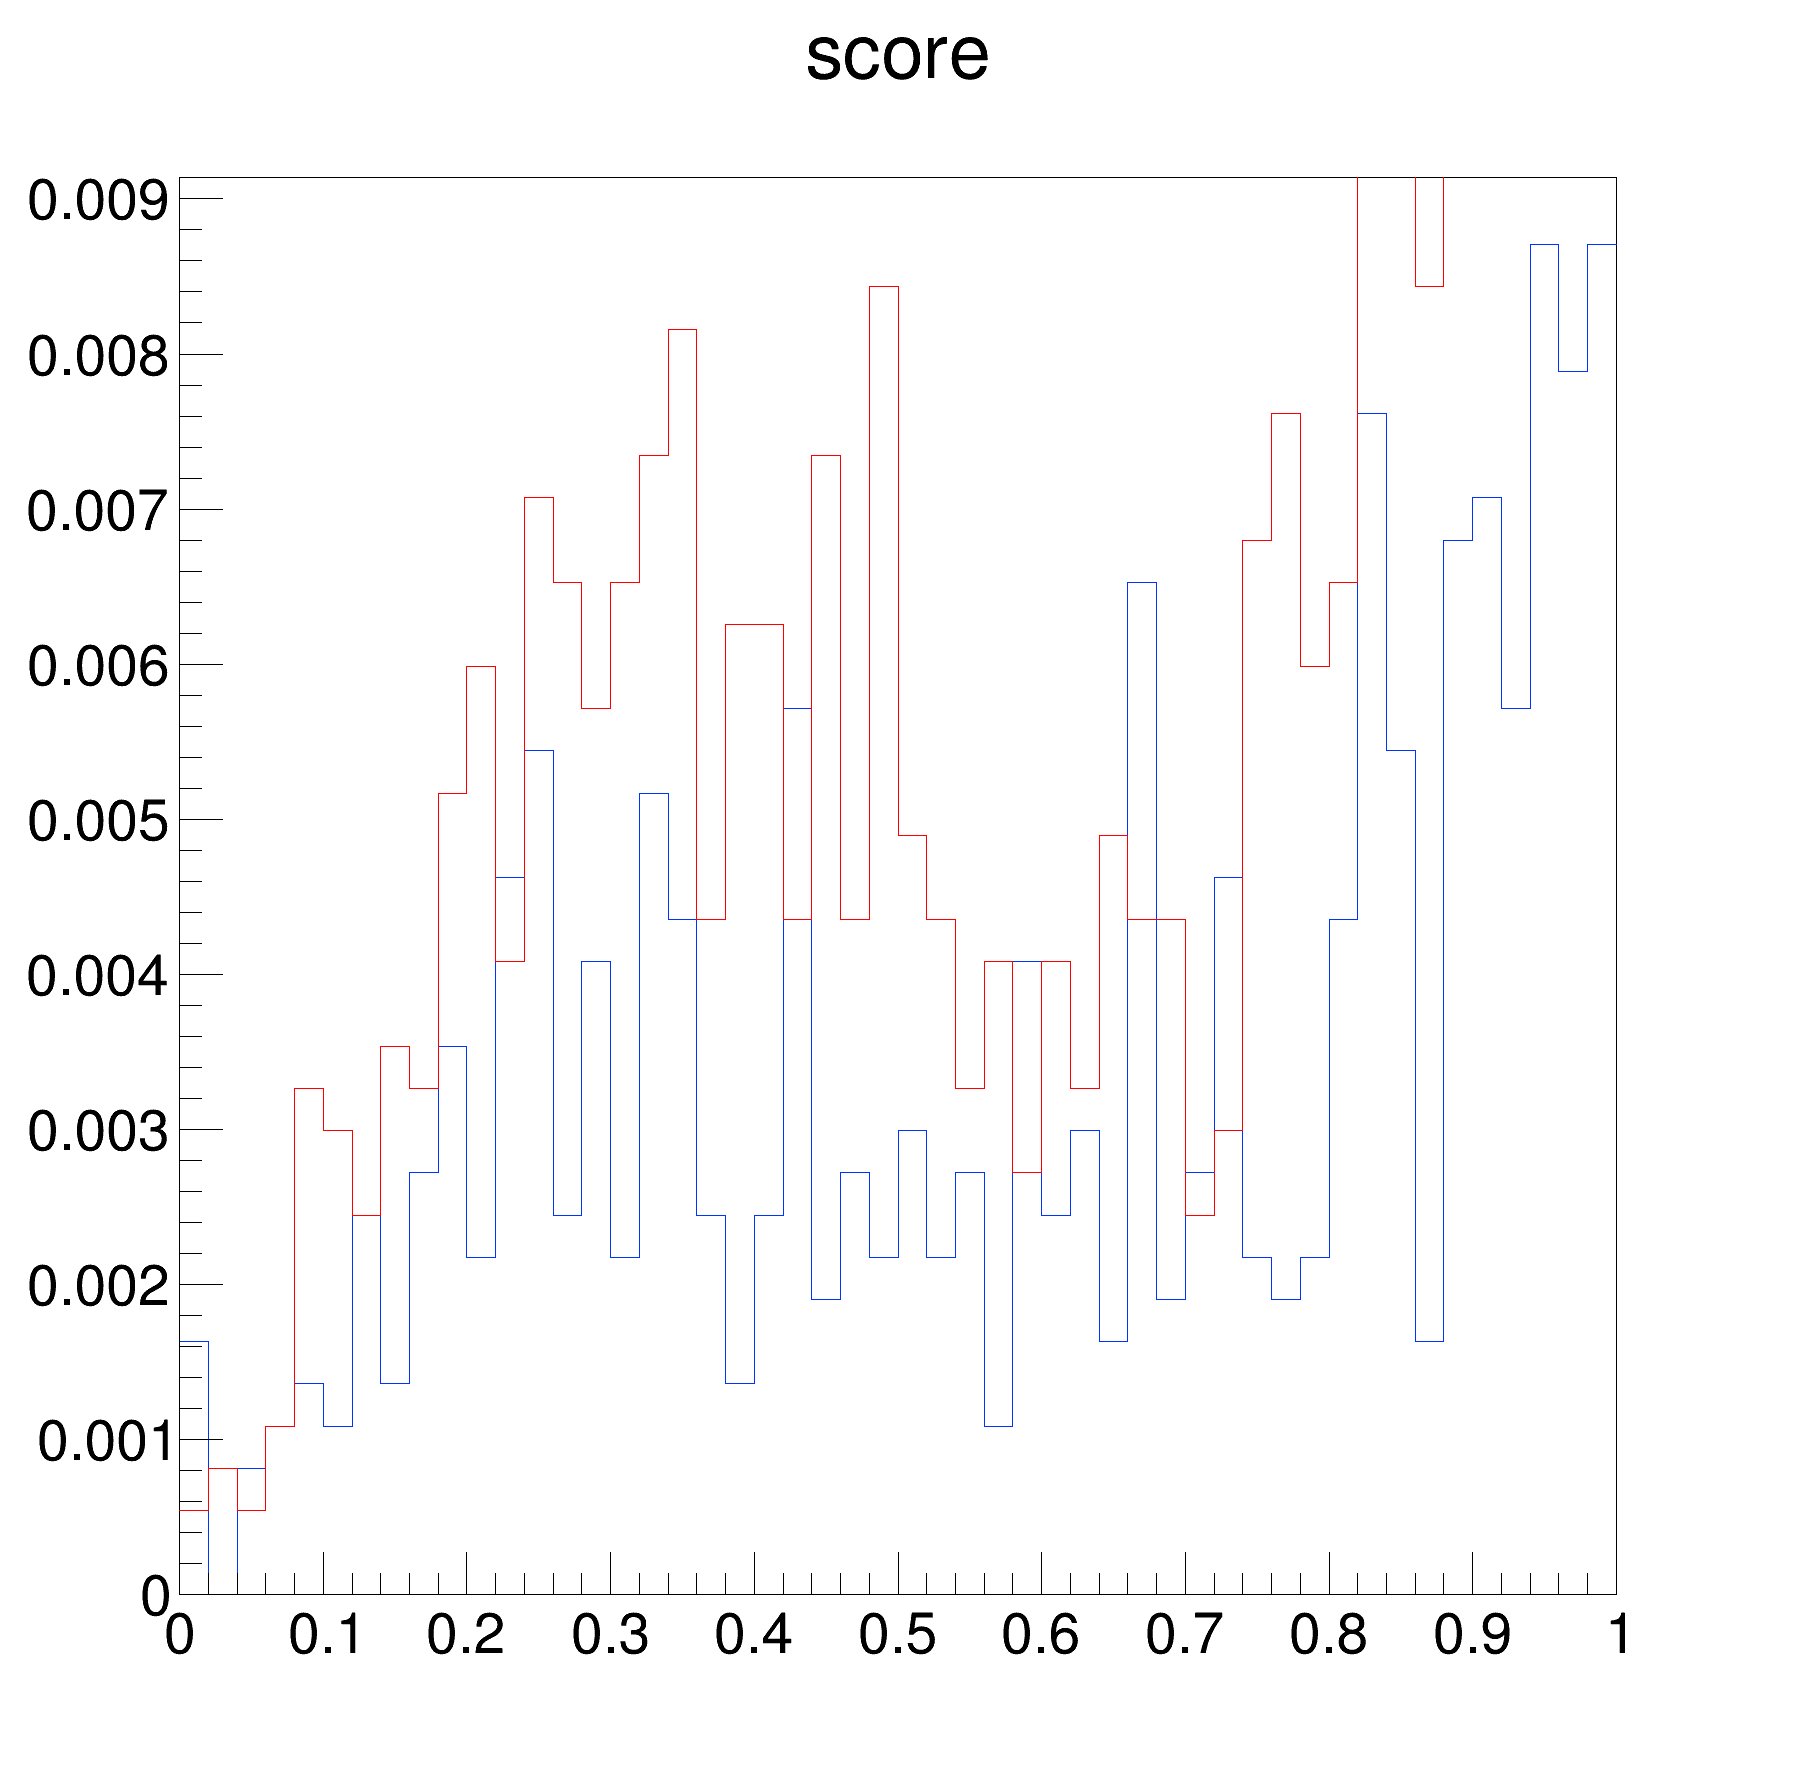

In [39]:
canvas = ROOT.TCanvas("","",1800, 1800)
canvas.cd()
c1= kAzure
c2 = kRed
c3 = kGreen
c4 = kViolet

h_sig.SetLineColor(c1)
h_sig_train.SetLineColor(c2)
h_bkg.SetLineColor(c3)
h_bkg_train.SetLineColor(c4)

h_sig.Draw("hist")
h_sig_train.Draw("hist same")
h_bkg.Draw("hist same")
h_bkg_train.Draw("hist same")

h_sig.SetStats(0)

canvas.Draw()

## KS test

In [28]:
import numpy as np
import ROOT

ROOT.TH1.SetDefaultSumw2()

In [92]:

statistics_sig = {}
p_values_sig = {}
statistic_bkg = 0
p_value_bkg = 0
qcd = True
qcd_2 = True
# Perform the KS test
for key in evalulation:
    
    score_sig = []
    score_bkg = []
    score_sig_2 = []
    score_bkg_2 = []
    weights_bkg = []
    weights_bkg_2 = []
    weights_sig = []
    weights_sig_2 = []
    for label, score, weight in zip(evalulation[key]["target_labels"], evalulation[key]["scores"],evalulation[key]["weight"] ):
        if label == 1:
            score_sig.append(score)
            weights_sig.append(weight)
        elif label == 0:
            score_bkg.append(score)
            weights_bkg.append(weight)

    for label, score, weight in zip(training[key]["target_labels"], training[key]["scores"], training[key]["weight"]):
        if label == 1:
            score_sig_2.append(score)
            weights_sig_2.append(weight)
        elif label == 0:
            score_bkg_2.append(score)
            weights_bkg_2.append(weight)
    break

In [104]:

bins = 50
h_sig = ROOT.TH1F("" ,"score", bins, 0, 1)
h_sig_2 = ROOT.TH1F("","score", bins, 0, 1)
h_bkg = ROOT.TH1F("","score", bins, 0, 1)
h_bkg_2 = ROOT.TH1F("", "score", bins, 0, 1)


h_sig.FillN(len(score_sig), np.array(score_sig , dtype=np.float64),np.array(weights_sig, dtype=np.float64))
h_sig_2.FillN(len(score_sig_2), np.array(score_sig_2, dtype=np.float64),np.array(weights_sig_2, dtype=np.float64))

h_bkg.FillN(len(score_bkg), np.array(score_bkg, dtype=np.float64),np.array(weights_bkg, dtype=np.float64))
h_bkg_2.FillN(len(score_bkg_2), np.array(score_bkg_2, dtype=np.float64),np.array(weights_bkg_2, dtype=np.float64))


ks_test_signal = h_sig_2.KolmogorovTest(h_sig)
ks_test_bkg = h_bkg_2.KolmogorovTest(h_bkg)

qcd_2 = False
qcd = False


In [105]:
ks_test_signal

1.9301105279075138e-05

In [106]:
ks_test_bkg

5.130721562624131e-06

In [99]:
len(score_sig)
np.array(weights_sig)

array([0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027202,
       0.00027202, 0.00027202, 0.00027202, 0.00027202, 0.00027

In [84]:
p_values_bkg

{'SVJ_700_0p3_LN5p': 0.026725265807089116,
 'SVJ_700_0p5_LN5p': 0.026725265807089116,
 'SVJ_700_0p7_LN5p': 0.026725265807089116,
 'SVJ_800_0p3_LN5p': 0.026725265807089116,
 'SVJ_800_0p5_LN5p': 0.026725265807089116,
 'SVJ_800_0p7_LN5p': 0.026725265807089116,
 'SVJ_900_0p3_LN5p': 0.026725265807089116,
 'SVJ_900_0p5_LN5p': 0.026725265807089116,
 'SVJ_900_0p7_LN5p': 0.026725265807089116,
 'SVJ_1000_0p3_LN5p': 0.026725265807089116,
 'SVJ_1000_0p5_LN5p': 0.026725265807089116,
 'SVJ_1000_0p7_LN5p': 0.026725265807089116,
 'SVJ_1100_0p3_LN5p': 0.026725265807089116,
 'SVJ_1100_0p5_LN5p': 0.026725265807089116,
 'SVJ_1100_0p7_LN5p': 0.026725265807089116,
 'SVJ_1200_0p3_LN5p': 0.026725265807089116,
 'SVJ_1200_0p5_LN5p': 0.026725265807089116,
 'SVJ_1200_0p7_LN5p': 0.026725265807089116,
 'SVJ_1300_0p3_LN5p': 0.026725265807089116,
 'SVJ_1300_0p5_LN5p': 0.026725265807089116,
 'SVJ_1300_0p7_LN5p': 0.026725265807089116,
 'SVJ_1400_0p3_LN5p': 0.026725265807089116,
 'SVJ_1400_0p5_LN5p': 0.02672526580708911